# Single Reactor Model

### Overview

This model simulates the behaviour of a single packed-bed reactor through the application of the first-principles model - including elements such as mass, energy conservation, reaction kinetics, Peng-Robinson equation of state (PR EoS), and catalyst properties - developed. The reactor is modelled as a $1-D$ axial dynamic system, with the objective of predicting the evolution of gas-phase species concentrations and bed temperature & pressure ofver time.

### Model Structure

The single-reactor model is developed around the following components:

1. **Thermodynamic properties:** Using PR EoS to calculate the gas mixture properties, including compressibility factor, enthalpy and internal energy.
2. **Pressure calculation:** Calculating the reactor pressure from gas micture temperature, composition and molar volume using PR Eos.
3. **Mass balances:** Determining the evolution of individual gas species concentration inside the reactor, accounting for chemical reaction, inlet and outlet flows.
4. **Energy balance:** Description of the reactor's thermal behaviour, accounting for the gas and catalyst internal energy, reaction contributions and relevant heat-transfer.
5. **Temperature calculation:** Numerically calculating the reactor bed temperature fromt he energy balance

### Modelling Approach
The reactor is represented as a dynamic system, with the governing mass and energy balances formulated as ordinary differential equations (ODEs) through the finite volume method (FVM) discretisation of their partial derivatives. 

The system is solved numerically using Pythons's scientific computing libraries. Numerical methods are applied, wehere relevant to evaluate thermodynamic properties, calculate pressure and solve for dependent variables. Additionally, the $solve_ivp$ function is used to integrate the govenring differential equations over the simulation period.

The model serves as the basis for investigating the dynamic behaviour of the reactor under varying operating conditions, with particular emphasis on its response to dynamic and intermiettent operation.



# Model Assumptions

The assumptions below apply to the model at its current stage, which covers the PR-EoS, the reaction kinetics, the mass balance and the energy balance.

### 1. System and species

1. The reactor is a single 1-D adiabatic packed bed. Radial gradients are neglected, and the flow is axial only (Rosbo et al. 2023, Assumptions A1 and A2).
2. The gas phase has three species, $\mathrm{H_2}$, $\mathrm{N_2}$ and $\mathrm{NH_3}$. Argon is excluded because the loop is assumed to use a cryogenic distillation column, giving a high-purity feed in which the argon content is negligible. The feed mole fractions $y_{k,0}$ are calculated over these three species only.

### 2. Thermodynamics

3. The gas is described by the Peng-Robinson equation of state with van der Waals mixing rules. The binary interaction parameters are set to $K_{ij} = 0$ as placeholders. Neither the DTU papers (Rosbo et al. 2023, 2026) nor the ThermoLib technical report (Ritschel et al. 2016) give $K_{ij}$ values for $\mathrm{H_2}$, $\mathrm{N_2}$ and $\mathrm{NH_3}$.
4. The ideal-gas heat capacity is the Shomate polynomial in $t = T/1000$, with constants from the NIST Chemistry WebBook. The DTU model uses the DIPPR correlation through ThermoLib. The $\mathrm{N_2}$ constants change at $T = 500\ \mathrm{K}$, so the $\mathrm{N_2}$ integral is split at that temperature.

### 3. Reaction kinetics

5. The reaction $\mathrm{N_2 + 3H_2 \rightleftharpoons 2NH_3}$ follows the Temkin-Pyzhev rate expression with $\alpha_{cat} = 4.75$. The rate is per $\mathrm{m^3}$ of catalyst, in $\mathrm{mol\,m^{-3}_{cat}\,s^{-1}}$. The pre-exponential factors and $E_{a,1}$ are the same in Rosbo et al. (2023) and Morud and Skogestad (1998).
6. The reverse activation energy is $E_{a,-1} = 198{,}464\ \mathrm{J\,mol^{-1}}$ from Morud and Skogestad (1998). Rosbo et al. (2023) prints $194{,}464\ \mathrm{J\,mol^{-1}}$. The rate uses ideal partial pressures $p_k = y_kP$ in bar, not fugacities, as in the DTU rate expression.

### 4. Mass balance

7. **Axial dispersion.** $D_{ax} = 0\ \mathrm{m^2\,s^{-1}}$. The DTU model of Rosbo et al. does not include axial dispersion in its governing equations. In Rosbo et al. (2023), Assumption A2 states perfect plug flow, with no back-mixing or diffusive flux, and the component molar flow is pure advection (Eq. 11). The cell balances in Rosbo et al. (2026) (Eq. 6a and 7a) contain only the upwind convective flux. The dispersion terms stay in the cell equations, so $D_{ax}$ is kept at zero until a correlation for the effective axial dispersion coefficient is available, and then only this value changes.
8. The convective flux is upwind. This adds numerical diffusion of $D_{num} = v_{in}\Delta z/2$. Rosbo et al. (2026), Section 2.10, report that $N = 10$ cells introduces a numerical diffusive error of the same magnitude as the dispersive backmixing in the beds (Morud and Skogestad, 1998). This model uses $N = 10$.
9. The inlet follows the Danckwerts condition, with the inlet flux equal to the feed flux. The outlet has zero concentration gradient.
10. The initial condition is a bed filled with feed gas in every cell, so the first seconds show a start-up transient.

### 5. Simplifications at this stage

11. The temperature of each cell, $T_i$, is calculated from the energy balance. The pressure is held at $P_0$ in the kinetics and in the thermodynamic properties.
12. The velocity is held constant at $v_{in} = v_{s0}/\varepsilon_B$ along the bed. The total concentration from the mass balance, $C_{tot,i}$, therefore differs from the PR-EoS concentration at $(T_i, P_0, y_i)$. The velocity coupling will be done at a later stage.

### 6. Parameter sources

13. The bed, catalyst and feed parameters are taken from Rosbo et al. (2026) where stated. Where a value is not given in the 2026 paper, the value from Rosbo et al. (2023) is used. The kinetic constants are from Morud and Skogestad (1998) and Rosbo et al. (2023), as stated in item 6.

### 7. Energy balance

14. The bed is adiabatic (Rosbo et al. 2023, A1).
15. The gas and catalyst in a cell have the same temperature (Rosbo et al. 2023, A4).
16. The catalyst density $\rho_{cat}$ and heat capacity $c_{v,cat}$ are constant (Rosbo et al. 2023, Eq. 17).
17. The effective axial thermal conductivity is $\lambda_{eff} = 0\ \mathrm{W\,m^{-1}\,K^{-1}}$. The energy balance of Rosbo et al. (2026), Eq. 6b, has no conduction term.

# Import Libraries

In [126]:
from scipy.integrate import solve_ivp
from scipy.integrate import quad
from scipy.optimize import fsolve
from scipy.optimize import brentq
import numpy as np

# Parameters and Variables

This code requires a set of physical, thermodynamic, catalyst, kinetic and transport parameters to describe the behaviour of the gas mixture and catalyst bed.

In the PR-EoS equations, $i$ and $j$ are species. In the balance equations, $k$ is the species and $i$ is the cell.

### 1. General and reactor parameters

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $R$ | `R` | Universal gas constant. | $\mathrm{J\,mol^{-1}\,K^{-1}}$ |
| $L_B$ | `L_bed` | Bed length. | $\mathrm{m}$ |
| $D_B$ | `D_bed` | Bed diameter. | $\mathrm{m}$ |
| $A_c$ | `A_c` | Bed cross-sectional area. | $\mathrm{m^2}$ |
| $\varepsilon_B$ | `eps_B` | Bed void fraction. | - |
| $N$ | `N` | Number of cells in the bed. | - |
| $\Delta z$ | `delta_z` | Cell length. | $\mathrm{m}$ |
| $T_{ref}$ | `T_ref` | Reference temperature for enthalpy and internal energy. Written $T^\circ$ in the ideal-gas enthalpy equation. | $\mathrm{K}$ |

### 2. Gas-phase thermodynamic parameters

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $T_{c,i}$ | `Tc` | Critical temperature of each species. | $\mathrm{K}$ |
| $P_{c,i}$ | `Pc` | Critical pressure of each species. | $\mathrm{Pa}$ |
| $\omega_i$ | `omega` | Acentric factor of each species. | - |
| $\Delta h_{f,i}^\circ$ | `hf` | Standard enthalpy of formation of each species. | $\mathrm{J\,mol^{-1}}$ |
| $A_i, B_i, C_i, D_i, E_i$ | `cP_constants` | Shomate heat capacity constants of each species. The $\mathrm{N_2}$ set applies above $500\ \mathrm{K}$. | $\mathrm{J\,mol^{-1}\,K^{-1}}$ |
| $A_i, B_i, C_i, D_i, E_i$ | `N2_low_constants` | Shomate heat capacity constants of $\mathrm{N_2}$ up to $500\ \mathrm{K}$. | $\mathrm{J\,mol^{-1}\,K^{-1}}$ |
| $K_{ij}$ | `K` | Binary interaction parameter of species pair $i,j$. | - |

### 3. Catalyst parameters

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $\rho_{cat}$ | `rho_cat` | Catalyst density per catalyst volume. | $\mathrm{kg\,m^{-3}}$ |
| $c_{v,cat}$ | `cv_cat` | Catalyst heat capacity. | $\mathrm{J\,kg^{-1}\,K^{-1}}$ |
| $\alpha_{cat}$ | `a_cat` | Catalyst activity factor. | - |

### 4. Reaction kinetic parameters

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $A_1$ | `A['A1']` | Pre-exponential factor of the forward reaction, $j = 1$. | $\mathrm{mol\,m^{-3}_{cat}\,s^{-1}\,bar^{-1.5}}$ |
| $A_{-1}$ | `A['A2']` | Pre-exponential factor of the reverse reaction, $j = -1$. | $\mathrm{mol\,m^{-3}_{cat}\,s^{-1}\,bar^{0.5}}$ |
| $E_{a,1}$ | `Ea['Ea1']` | Activation energy of the forward reaction. | $\mathrm{J\,mol^{-1}}$ |
| $E_{a,-1}$ | `Ea['Ea2']` | Activation energy of the reverse reaction. | $\mathrm{J\,mol^{-1}}$ |
| $\nu_k$ | `nu` | Stoichiometric coefficient of each species. | - |

### 5. Transport parameters

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $D_{ax}$ | `D_ax` | Axial dispersion coefficient. Written $D$ in the mass balance equations. | $\mathrm{m^2\,s^{-1}}$ |
| $\lambda_{eff}$ | `lambda_eff` | Effective axial thermal conductivity. | $\mathrm{W\,m^{-1}\,K^{-1}}$ |

### 6. Initial and operating conditions

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $T_0$ | `T0` | Initial bed temperature and feed temperature. | $\mathrm{K}$ |
| $P_0$ | `P0` | Initial and feed pressure, held constant along the bed. | $\mathrm{Pa}$ |
| $T$ | `T` | Temperature of the first PR-EoS calculations, equal to $T_0$. | $\mathrm{K}$ |
| $P$ | `P` | Pressure of the first PR-EoS calculations, equal to $P_0$. | $\mathrm{Pa}$ |
| $F_{k,in}$ | `F_in` | Inlet molar flow rate of each species. | $\mathrm{mol\,s^{-1}}$ |
| $F_{tot,in}$ | `F_in_total` | Total inlet molar flow rate. | $\mathrm{mol\,s^{-1}}$ |
| $y_{k,0}$ | `y0` | Feed mole fraction of each species. | - |
| $y_i$ | `y` | Mole fractions of the first PR-EoS calculations, equal to $y_{k,0}$. | - |
| $v_{s0}$ | `v_s0` | Superficial velocity at the feed. | $\mathrm{m\,s^{-1}}$ |
| $v_{in}$ | `v_in` | Interstitial inlet velocity, used at every face. | $\mathrm{m\,s^{-1}}$ |
| $C_{k,in}$ | `C_in` | Feed concentration of each species. | $\mathrm{mol\,m^{-3}}$ |
| $C_{k,i}(0)$ | `C0` | Initial concentration of each species in each cell. | $\mathrm{mol\,m^{-3}}$ |
| $h_{m,in}$ | `h_in` | Feed enthalpy per gas volume. | $\mathrm{J\,m^{-3}}$ |
| $u_i(0)$ | `u_bed_0` | Initial internal energy per bed volume. | $\mathrm{J\,m^{-3}}$ |
| $t_{end}$ | `t_end` | Simulation time. | $\mathrm{s}$ |

### 7. Calculated variables: PR-EoS and kinetics

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $\kappa_i$ | `kappa` | PR-EoS acentric factor function. | - |
| $\alpha_i$ | `alpha` | PR-EoS temperature correction. | - |
| $a_{c,i}$ | `a_c` | Attraction parameter at the critical point. | $\mathrm{Pa\,m^6\,mol^{-2}}$ |
| $a_i$ | `a` | Component attraction parameter. | $\mathrm{Pa\,m^6\,mol^{-2}}$ |
| $b_i$ | `b` | Component co-volume. | $\mathrm{m^3\,mol^{-1}}$ |
| $a_m$ | `a_m`, `amix` | Mixture attraction parameter. | $\mathrm{Pa\,m^6\,mol^{-2}}$ |
| $b_m$ | `b_m`, `bmix` | Mixture co-volume. | $\mathrm{m^3\,mol^{-1}}$ |
| $v_m$ | `vmix` | Molar volume of the gas mixture. | $\mathrm{m^3\,mol^{-1}}$ |
| $Z$ | `Z` | Compressibility factor. | - |
| $B$ | `B` | Dimensionless mixture co-volume. | - |
| $C_{total}$ | `c_total` | Total concentration from the PR-EoS, $1/v_m$. | $\mathrm{mol\,m^{-3}}$ |
| $d\alpha_i/dT$ | `dalpha_dT` | Temperature derivative of $\alpha_i$. | $\mathrm{K^{-1}}$ |
| $da_i/dT$ | `da_dT` | Temperature derivative of $a_i$. | $\mathrm{Pa\,m^6\,mol^{-2}\,K^{-1}}$ |
| $da_m/dT$ | `da_m` | Temperature derivative of $a_m$. | $\mathrm{Pa\,m^6\,mol^{-2}\,K^{-1}}$ |
| $h_m^{ig}$ | `dh_ig_m` | Ideal-gas enthalpy per gas volume. | $\mathrm{J\,m^{-3}}$ |
| $h_m^R / v_m$ | `h_residual` | Residual enthalpy per gas volume. | $\mathrm{J\,m^{-3}}$ |
| $h_{PR}$ | `hmix` | Mixture enthalpy per gas volume. | $\mathrm{J\,m^{-3}}$ |
| $u_{PR}$ | `umix` | Mixture internal energy per gas volume, $h_{PR} - P$. | $\mathrm{J\,m^{-3}}$ |
| $k_j$ | `k` | Reaction rate constant. | Same as $A_j$ |
| $p_i$ | `p_bar` | Partial pressure of each species. | $\mathrm{bar}$ |
| $r_{N_2}$ | `r_N2` | Net rate of $\mathrm{N_2}$ consumption. | $\mathrm{mol\,m^{-3}_{cat}\,s^{-1}}$ |

### 8. Calculated variables: mass and energy balances

| Mathematical symbol | Variable name | Description | Units |
| --- | --- | --- | --- |
| $C_{k,i}$ | `C` | Concentration of species $k$ in cell $i$. | $\mathrm{mol\,m^{-3}}$ |
| $C_{tot,i}$ | `C_tot` | Total concentration in cell $i$ from the mass balance. | $\mathrm{mol\,m^{-3}}$ |
| $y_{k,i}$ | `y_i` | Mole fraction of species $k$ in cell $i$. | - |
| $T_i$ | `T_i`, `T_cell` | Temperature of cell $i$. | $\mathrm{K}$ |
| $\tilde{h}_i$ | `hmix_i * vmix_i` | Molar enthalpy of the gas in cell $i$. | $\mathrm{J\,mol^{-1}}$ |
| $\tilde{u}_i$ | `umix * vmix` | Molar internal energy of the gas, in the temperature solver. | $\mathrm{J\,mol^{-1}}$ |
| $h_{m,i}$ | `h_gas` | Gas enthalpy per gas volume in cell $i$. | $\mathrm{J\,m^{-3}}$ |
| $u_i$ | `u_bed` | Internal energy per bed volume in cell $i$. | $\mathrm{J\,m^{-3}}$ |
| $dC_{k,i}/dt$ | `dCdt` | Rate of change of concentration. | $\mathrm{mol\,m^{-3}\,s^{-1}}$ |
| $du_i/dt$ | `dudt` | Rate of change of internal energy. | $\mathrm{J\,m^{-3}\,s^{-1}}$ |
| $\mathbf{Y}$ | `Y` | List of all $C_{k,i}$ and $u_i$. | As per entry |
| $\mathbf{Y}(0)$ | `Y0` | Initial values of $\mathbf{Y}$. | As per entry |
| $p_{0,k}$ | `start` | Start of the block of species $k$ in $\mathbf{Y}$. | - |
| $p_{0,u}$ | `start_u` | Start of the internal energy block in $\mathbf{Y}$. | - |
| $t$ | `t` | Time. | $\mathrm{s}$ |
| $z_i$ | `z` | Position of the cell centre. | $\mathrm{m}$ |
| $\Phi_{E,1/2}$ | `Phi_in` | Energy flux entering the bed. | $\mathrm{J\,m^{-2}\,s^{-1}}$ |
| $\Phi_{E,N+1/2}$ | `Phi_out` | Energy flux leaving the bed. | $\mathrm{J\,m^{-2}\,s^{-1}}$ |

In [127]:
#Constants:

R = 8.314 #Universal gas constant in J/(mol*K)

Tc = {'H2': 33.145, 'N2': 126.192, 'NH3': 405.56} #Critical temperatures in K
Pc = {'H2': 1.2964e6, 'N2': 3.3958e6, 'NH3': 11.3634e6} #Critical pressures in Pa  #TML: use 1.2964e6 instead of 1.2964 * 10**6
omega = {'H2': -0.219, 'N2': 0.0372, 'NH3': 0.256} #Acentric factors
hf = {'H2': 0, 'N2': 0, 'NH3': -45.90 * 1000} #Enthalpy of formation in J/mol

#Ideal heat capacities constants
cP_constants = {'H2': {'A': 33.066178, 'B': -11.363417, 'C': 11.432816, 'D': -2.772874, 'E': -0.158558},
                'N2': {'A': 19.50583, 'B': 19.88705, 'C': -8.598535, 'D': 1.369784, 'E': 0.527601},
                'NH3': {'A': 19.99563, 'B': 49.77119, 'C': -15.37599, 'D': 1.921168, 'E': 0.189174}}
N2_low_constants = {'A': 28.98641, 'B': 1.853978, 'C': -9.647459, 'D': 16.63537, 'E': 0.000117}

# Binary interaction parameters for Peng-Robinson EOS:
# TML: you can also define an empty dictionary and then add entries to it, e.g., dict = {}; dict['key1'] = value1; dict['key2'] = value2; ...
K = {}
K['H2'] = {'H2': 0,   #TML: must include own entry
           'N2': 0,   #Binary interaction parameter for H2-N2 - currently using placeholders as I do not have the value yet
           'NH3':0}   #Binary interaction parameter for H2-NH3 - currently using placeholders as I do not have the value yet
K['N2'] = {'H2': 0,   #Binary interaction parameter for N2-H2 - currently using placeholders as I do not have the value yet   # TML: must repeat symmetric entries
           'N2': 0,   #TML: must include own entry
           'NH3': 0}  #Binary interaction parameter for N2-NH3 - currently using placeholders as I do not have the value yet
K['NH3'] = {'H2': 0,  #Binary interaction parameter for NH3-H2 - currently using placeholders as I do not have the value yet  # TML: must repeat symmetric entries
            'N2': 0,  #Binary interaction parameter for NH3-N2 - currently using placeholders as I do not have the value yet  # TML: must repeat symmetric entries
            'NH3':0}  #TML: must include own entry  

#Reactor properties - all taken from DTU paper:
L_bed = 0.8824 #Bed length in m - DTU paper Table 2
D_bed = 1.2 #Bed diameter in m - DTU paper Table 2
V_bed = np.pi * (D_bed/2)**2 * L_bed #Bed volume in m^3 - calculated from bed length and diameter

#Grid
N = 10 #Number of cells in the bed
delta_z = L_bed/N #Cell length in m - calculated from bed length and number of cells

#Catalyst properties - all taken from DTU paper:
eps_B = 0.33 #Bed void fraction - DTU paper Table 2
rho_cat = 3284 #Catalyst density in kg/m^3 - DTU paper Table 2
cv_cat = 1100 #Catalyst heat capacity in J/(kg*K) - DTU paper Table 2
d_p = 0.008 #Hydraulic diameter in m - DTU paper Table 2
A_c = np.pi * (D_bed/2)**2 #Cross-sectional area of the bed in m^2 - calculated from bed diameter

#Reaction parameters - all taken from DTU paper, except Ea2 which is from Morud & Skogestad:
Ea = {'Ea1' : 87090, 'Ea2' : 198464}#activation energy in J/mol for the reaction - Morud & Skogestad
a_cat = 4.75 #Catalyst activity factor, DTU paper and Morud & Skogestad 1998 paper
A = {'A1' : 1.79e4 * 1000/3600 , 'A2' : 2.57e16 * 1000/3600} #pre-exponential factors, converted from kmol/(h m^3 cat) to mol/(s m^3 cat)
nu = {'H2': -3, 'N2': -1, 'NH3': 2} #Stoichiometric coefficients for the reaction

#Axial dispersion parameters - using placeholders for now, as I do not have the values yet:
D_ax = 0 #Axial dispersion coefficient in m^2/s - set to zero: DTU (Rosbo et al.) assume plug flow with no dispersion in the governing equations; kept at zero until a correlation for the effective dispersion coefficient is available
lambda_eff = 0 #Effective axial thermal conductivity in W/(m K) - set to zero: the DTU 2026 energy balance has no conduction term; kept at zero until a correlation is available

#System parameters of mixture at feed:
T_ref = 298.15 #Reference temperature in K
T0 = 717 #Initial temperature in K
T = T0 #Current temperature in K
P0 = 213.3e5 #Initial pressure in Pa
P = P0 #Current pressure in Pa 
F_in = {'H2': 4078 * 1000/3600, 'N2': 1360 * 1000/3600, 'NH3': 236.7 * 1000/3600} #Inlet molar flow rates in mol/s
F_in_total = sum(F_in.values()) #Total inlet molar flow rate in mol/s
M = {'H2': 2.016, 'N2': 28.014, 'NH3': 17.031} #Molar masses in g/mol
y0 = {'H2': F_in['H2']/F_in_total, 'N2': F_in['N2']/F_in_total, 'NH3': F_in['NH3']/F_in_total} #Initial species composition in mole fraction
y = y0.copy() #Species composition used for the PR calculations at the feed state in mole fraction
# C = {'H2': 0.5, 'N2': 0.5, 'NH3': 0} #Initial species composition in mol/m^3
# C0 = sum(C.values()) #Initial total concentration in mol/m^3
# y = {'H2': C['H2']/C0, 'N2': C['N2']/C0, 'NH3': C['NH3']/C0} #Initial species composition in mole fraction

# Peng Robinsons EOS's calculator 
This section of the notebook uses the Peng Robinson's equation of state (PR-EoS) to calculate the volume of fluid, provided the temperature, pressure, and critical properties. The PR-EoS is given below:

$$ P = \frac{RT}{v_m-b_m} - \frac{a_m}{v_m(v_m+b_m)+b_m(v_m-b_m)} $$

Where:

$$ a_m = \sum_i \sum_j {y_i y_j (1 - K_{ij})\sqrt{a_i a_j}} $$
$$ b_m = \sum{y_i b_i} $$

The function below is used to calculate the component parameters $\alpha_i$, $\kappa_i$, $a_i$, $b_i$ and $a_c$ using the following equations:

$$ \kappa_i = 0.37464 + 1.54226 \omega_i - 0.26992 \omega_i^2 $$
$$ \alpha_i = [1 + \kappa_i (1-\sqrt{\frac{T}{T_{c,i}}})]^2 $$
$$ a_{c,i} =  0.45724  \frac{R^2 T_{c,i}^2}{P_c} $$
$$ a_i = a_{c,i} \alpha_i $$
$$ b_i = 0.07779 \frac{R T_c}{P_c} $$



In [128]:
def component_parameters_calculation(T, Tc, Pc, omega):
    a_c = 0.45724 * R**2 * Tc**2 / Pc
    kappa = 0.37464 + 1.54226 * omega - 0.26992 * omega**2
    alpha = (1 + kappa * (1 - (T / Tc)**0.5))**2
    a = a_c * alpha
    b = 0.07779 * R * Tc / Pc
    return a, b, a_c, kappa

def component_parameters(T,y):
    a, b, a_c, kappa = {}, {}, {}, {}
    for component in y:
        a[component], b[component],a_c[component],kappa[component] = component_parameters_calculation(T, Tc[component], Pc[component], omega[component])
    return a, b, a_c, kappa

a, b, a_c, kappa = component_parameters(T,y)

The function below is used to calculate the mixture parameters $a_m$ and $b_m$ using the following equations:

$$ a_m = \sum_i \sum_j {y_i y_j (1 - K_{ij})\sqrt{a_i a_j}} $$
$$ b_m = \sum{y_i b_i} $$

In [129]:
# TML: we can write the individual terms in the summation. It looks more like the original mathematical expression, which is referenced directly above.
def mixture_parameters(y, a, b, K):
    a_m, b_m = 0, 0
    for component_1 in y:
        b_m += y[component_1]*b[component_1]
        for component_2 in y:
            a_m += y[component_1]*y[component_2] * (1- K[component_1][component_2]) * (a[component_1] * a[component_2])**0.5
    return a_m, b_m

a_m, b_m = mixture_parameters(y, a, b, K)

The function below uses the Peng-Robinson EoS to calculate the volume and pressure of the fluid using the following equation:

$$ P = \frac{RT}{v_m-b_m} - \frac{a_m}{v_m(v_m+b_m)+b_m(v_m-b_m)} $$

In [130]:
def volume (T, P, a_m,b_m):
     v_m0 = R * T / P #Initial guess for molar volume in m^3/mol
     volume = lambda v_m: (P - R*T / (v_m - b_m) + a_m / (v_m * (v_m + b_m) + b_m * (v_m - b_m)))  #TML: better to define one line function as lambda function
     v_m = fsolve(volume, (v_m0))[0] #Molar volume of the mixture in m^3/mol
     return(v_m)

vmix = volume (T, P, a_m,b_m)
print(f"Volume of the gas mixture: {vmix:.8f} m^3/mol")

def pressure (T, v_m, a_m,b_m):
    P = R*T / (v_m - b_m) - a_m / (v_m * (v_m + b_m) + b_m * (v_m - b_m)) #Pressure in Pa
    return P

Volume of the gas mixture: 0.00029443 m^3/mol


The function below is used to calculate the ideal gas enthalpy change and compressibility factor of the mixture using the following equations:

$$ c_{p,i} (T)= A_i + B_i t +C_i t^2 + D_i t^3 + \frac {E_i}{t^2} $$
where, $$ t = \frac{T}{1000}$$

and,
$$ h_m^{ig} = \sum_i c_i \left(\Delta h_{f,i}^\circ + \int_{T^\circ}^{T} c_{p,i}^{ig}(T)\,dT\right), \qquad c_i = \frac{y_i}{v_m} $$
$$ Z = \frac {Pv_m}{RT}$$
$$ B = \frac{b_mP}{RT} $$


The $\mathrm{N_2}$ constants $A_i \dots E_i$ change at $T = 500\ \mathrm{K}$. Below 500 K the low-temperature set is used, above it the high-temperature set.






In [131]:
Z = P * vmix / (R * T)
B = b_m * P / (R * T)

def h_ig_vol (T, vmix, y, hf):
    integrand_cP = lambda T, A, B, C, D, E: A + B * T / 1000 + C * (T / 1000)**2 + D * (T / 1000)**3 + E / (T / 1000)**2
    c, dh_ig_m = 1/vmix, 0
    for component in y:
        if component == 'N2' and T > 500: #N2 constants change at 500 K, so the integral is done in two parts
            cl = N2_low_constants
            ch = cP_constants['N2']
            cp_int = quad(integrand_cP, T_ref, 500, args=(cl['A'], cl['B'], cl['C'], cl['D'], cl['E']))[0] \
                   + quad(integrand_cP, 500, T, args=(ch['A'], ch['B'], ch['C'], ch['D'], ch['E']))[0]
        elif component == 'N2': #T <= 500 K, only the low-temperature constants apply
            cl = N2_low_constants
            cp_int = quad(integrand_cP, T_ref, T, args=(cl['A'], cl['B'], cl['C'], cl['D'], cl['E']))[0]
        else:
            cc = cP_constants[component]
            cp_int = quad(integrand_cP, T_ref, T, args=(cc['A'], cc['B'], cc['C'], cc['D'], cc['E']))[0]
        dh_ig_m += y[component] * (hf[component] + cp_int) #cp_int in J/mol
        # c += y[component] * P / (Z * R * T)
        
    dh_ig_m = c * (dh_ig_m)
    return (c, dh_ig_m)
    
c_total, dh_ig_m = h_ig_vol (T, vmix, y, hf)

The function below is used to calculate the residual enthalpies for each of the components and ultimately, the enthalpy of the mixture using the following equations:

$$ \frac{d\alpha_i}{dT} = - \frac{\kappa_i (1 + \kappa_i (1-\sqrt{\frac{T}{T_{c,i}}}))}{\sqrt{TT_{c,i}}} $$

$$ \frac{da_i}{dT} = a_{c,i} \frac{d\alpha_i}{dT} $$

$$ \frac {da_m}{dT} = \sum_i \sum_j {y_i y_j (1 - K_{ij})} \frac{1}{2} (\sqrt{\frac{a_j}{a_i}} \frac{da_i}{dT} + \sqrt{\frac{a_i}{a_j}}\frac{da_j}{dT}) $$

$$ h_m^R = RT(Z-1) + \frac{T\frac{da_m}{dT} - a_m}{2\sqrt{2}\,b_m}\ln\left(\frac{Z + (1+\sqrt{2})B}{Z + (1-\sqrt{2})B}\right) $$

In [132]:
def enthalpy (T, y, a, kappa, Tc, a_c, a_m, b_m, K, c, dh_ig_m, Z, B):    
    dalpha_dT = lambda T, kappa, Tc: -kappa * (1 + kappa * (1 - (T / Tc)**0.5)) / ((T * Tc)**0.5)
    da_dT = {}
    da_m = 0
    for component_1 in y:
        da_dT[component_1] = a_c[component_1] * dalpha_dT(T, kappa[component_1], Tc[component_1])

    for component_1 in y:
            for component_2 in y:
                da_m += y[component_1]*y[component_2]*(1 - K[component_1][component_2]) * 0.5 \
                * ((a[component_2]/a[component_1])**0.5 * da_dT[component_1] + (a[component_1]/a[component_2])**0.5 * da_dT[component_2])

    h_residual = c * (R * T * (Z - 1) + (T * da_m - a_m) / (b_m * 2 * 2**0.5) * np.log((Z + B * (1 + 2**0.5)) / (Z + B * (1 - 2**0.5))))
    h_m = dh_ig_m + h_residual
    return h_m

hmix = enthalpy(T, y, a, kappa, Tc, a_c, a_m, b_m, K, c_total, dh_ig_m, Z, B)

print(f"Enthalpy of the gas mixture: {hmix:.2f} J/m^3, which is kinda equal to {hmix:.3e} J/m^3")


Enthalpy of the gas mixture: 36583342.94 J/m^3, which is kinda equal to 3.658e+07 J/m^3


## Final Call Function

The function below combines all the calculations done in this notebook into a single call. It takes an input of temperature, pressure and molar composition of the mixture and returns the molar volume, total molar concentration and enthalpy of the mixture per unit volume of gas. 

It also returns the compressibility factor and the internal energy of the mixture per unit volume of gas:

$$ h_{PR} = h_m^{ig} + \frac{h_m^R}{v_m}, \qquad u_{PR} = h_{PR} - P $$

In [133]:
def properties (T, P, y):
    a, b, a_c, kappa = component_parameters(T,y)
    amix, bmix = mixture_parameters(y, a, b, K)
    vmix = volume (T, P, amix, bmix)
    Z = P * vmix / (R * T)
    B = bmix * P / (R * T)
    c_total, dh_ig_m = h_ig_vol(T, vmix, y, hf)
    hmix = enthalpy(T, y, a, kappa, Tc, a_c, amix, bmix, K, c_total, dh_ig_m, Z, B)
    umix = hmix - P
    return vmix, hmix, c_total, umix, Z

#### Reaction kinetics

The reaction rate is determined for each cell using the relevant concentrations and operating conditions of the respective cell. The ammonia synthesis reaction is as follows:

$$
N_2 + 3H_2 \rightleftharpoons 2NH_3

$$

Temkin-Pyzhev kinetic model is used for the ammonia reaction and described below:

$$
r_{N_2} = \alpha_{cat}\left(k_1\,p_{N_2}\frac{p_{H_2}^{1.5}}{p_{NH_3}} - k_{-1}\frac{p_{NH_3}}{p_{H_2}^{1.5}}\right)
$$

where,

$$
k_j = A_j \exp\left(\frac{-E_{a,j}}{RT}\right), \qquad j = 1, -1
$$

$p_i = y_i P / 10^5$ is the partial pressure in bar. 

In [134]:
def reaction_rate (T, P, y):
    k = {}
    for reaction in ['1', '2']:
        k[reaction] = A['A' + reaction] * np.exp(-Ea['Ea' + reaction] / (R * T)) #Reaction rate constant k1 in mol/(m^3 cat*s*bar^1.5), k2 in mol*bar^0.5/(m^3 cat*s)

    p_bar = {}
    for component in y:
        p_bar[component] = y[component] * P / 1e5 #Partial pressure in bar

    r_N2 = a_cat * (k['1'] * p_bar['N2'] * p_bar['H2']**1.5/p_bar['NH3'] - k['2'] * p_bar['NH3']/p_bar['H2']**1.5) #Net rate of N2 consumption in mol/(m^3 cat*s)
    return r_N2


# Mass Balance Solution

#### Initial Conditions

The initial species concentrations are calculated using the initial mole fractions and the total molar concentration from the `properties()` function:

$$ C_{k,i}(0) = y_{k,0}\,C_{total} $$

The feed concentrations are calculated in the same way:

$$ C_{k,in} = y_{k,0}\,C_{total} $$

The superficial and interstitial velocities at the feed are:

$$ v_{s0} = \frac{v_m\,F_{tot,in}}{A_c}, \qquad v_{in} = \frac{v_{s0}}{\varepsilon_B} $$

##### Inlet cell ($i = 1$) of the mass balance

The inlet face flux is set by the Danckwerts condition that the total flux entering the reactor bed is equal to the feed flux:

$$\Phi_{k,1/2} = \epsilon_B v_{in}\,C_{k,in}$$

This is equivalent to a ghost cell upstream of cell 1 with
$C_{k,0} = \dfrac{\epsilon_B v_{in}\,C_{k,in} + (D/\Delta z)\,C_{k,1}}{\epsilon_B v_{in} + D/\Delta z}$.

The cell 1 equation is then:

$$\frac{dC_{k,1}}{dt} =
-\frac{v_{3/2}\,C_{k,1} - v_{in}\,C_{k,in}}{\Delta z}
+ \frac{D}{\epsilon_B}\,\frac{C_{k,2} - C_{k,1}}{\Delta z^2}
+ \frac{1 - \epsilon_B}{\epsilon_B}\,\nu_k\,r_{N_2,1}$$

In [135]:
vmix, hmix, c_total, umix, Z = properties (T0, P0, y0)
v_s0 = vmix * F_in_total / A_c #Superficial velocity at feed in m/s
v_in = v_s0 / eps_B #Interstitital inlet velocity in m/s
C0 = {}
for component in y0:
    C0[component] = np.full(N, y0[component]*c_total) #Initial concentration of each component in mol/m^3 - set it equal to feed concentration for all cells in the bed

C_in = {}
for component in y0:
    C_in[component] = y0[component] * c_total #Feed concentration at the inlet in mol/m^3

for component in C0:
    print(f"Initial {component} concentrations: {C0[component]} mol/m^3")

def inlet_concentration (v_l, C_l, v_r, C_i, C_r, D, nu_k, r_N2_1):
    dC_1_dt = -(v_r * C_i - v_l * C_l)/delta_z \
    + D/eps_B * (C_r - C_i)/delta_z**2 \
    + (1 - eps_B)/eps_B * nu_k * r_N2_1 #mol/(m^3*s)
    return dC_1_dt

#test lines

r_N2 = reaction_rate(T0, P0, y0)
s = 'H2'

dC_1_dt = inlet_concentration(
    v_in, C_in[s], v_in, C0[s][0], C0[s][1],
    D_ax, nu[s], r_N2
)


Initial H2 concentrations: [2440.76055902 2440.76055902 2440.76055902 2440.76055902 2440.76055902
 2440.76055902 2440.76055902 2440.76055902 2440.76055902 2440.76055902] mol/m^3
Initial N2 concentrations: [813.98586568 813.98586568 813.98586568 813.98586568 813.98586568
 813.98586568 813.98586568 813.98586568 813.98586568 813.98586568] mol/m^3
Initial NH3 concentrations: [141.66945177 141.66945177 141.66945177 141.66945177 141.66945177
 141.66945177 141.66945177 141.66945177 141.66945177 141.66945177] mol/m^3


##### Interior cells ($i = 2, \dots, N-1$) of the mass balance

Interior cells share faces with neighbouring cells on both the right and left hand side.. The flux through each face is the sum of the convective and dispersive fluxes. The convection takes an upwind scheme, therefore, the concentration at a face is equal to the concentration of the cell upstream to it - this follows the direction of the flow since gas flows downstream through the reactor. Dispersion is a central difference across the face:

$$\Phi_{k,i-1/2} = \varepsilon_B v_{i-1/2}\,C_{k,i-1} - D\,\frac{C_{k,i} - C_{k,i-1}}{\Delta z}$$

$$\Phi_{k,i+1/2} = \varepsilon_B v_{i+1/2}\,C_{k,i} - D\,\frac{C_{k,i+1} - C_{k,i}}{\Delta z}$$

The balance on the gas volume of the cell, $\epsilon_B A_c \Delta z$, is:

$$\varepsilon_B A_c \Delta z\,\frac{dC_{k,i}}{dt} = A_c\left(\Phi_{k,i-1/2} - \Phi_{k,i+1/2}\right) + A_c \Delta z\,(1 - \varepsilon_B)\,\nu_k\,r_{N_2,i}$$

Substituting the fluxes and dividing by $\varepsilon_B A_c \Delta z$, the cell $i$ equation is:

$$\frac{dC_{k,i}}{dt} =
-\frac{v_{i+1/2}\,C_{k,i} - v_{i-1/2}\,C_{k,i-1}}{\Delta z}
+ \frac{D}{\varepsilon_B}\,\frac{C_{k,i+1} - 2C_{k,i} + C_{k,i-1}}{\Delta z^2}
+ \frac{1 - \varepsilon_B}{\varepsilon_B}\,\nu_k\,r_{N_2,i}$$

In [136]:
def interior_concentration (v_l, C_l, v_r, C_i, C_r, D, nu_k, r_N2_1):
    dC_1_dt = -(v_r * C_i - v_l * C_l)/delta_z \
    + D/eps_B * (C_r - 2 * C_i + C_l)/delta_z**2 \
    + (1 - eps_B)/eps_B * nu_k * r_N2_1 #mol/(m^3*s)
    return dC_1_dt

##### Outlet cell ($i = N$) of the mass balance

The outlet cell has a left hand side face shared with cell $N-1$ and a right hand side face at the end of the bed. The convective flux through the left face is upwind, as in the interior cells, so it takes the concentration of cell $N-1$.

At the right face, the outlet condition is zero concentration gradient:

$$\left.\frac{\partial C_k}{\partial z}\right|_{z=L} = 0$$

This means there is no dispersive flux through the right face. The convective flux leaves with the concentration of the outlet cell itself, which is the upwind value for this face:

$$\Phi_{k,N-1/2} = \epsilon_B v_{N-1/2}\,C_{k,N-1} - D\,\frac{C_{k,N} - C_{k,N-1}}{\Delta z}$$

$$\Phi_{k,N+1/2} = \epsilon_B v_{N+1/2}\,C_{k,N}$$

The balance on the gas volume of the cell, $\epsilon_B A_c \Delta z$, is:

$$\epsilon_B A_c \Delta z\,\frac{dC_{k,N}}{dt} = A_c\left(\Phi_{k,N-1/2} - \Phi_{k,N+1/2}\right) + A_c \Delta z\,(1 - \epsilon_B)\,\nu_k\,r_{N_2,N}$$

Substituting the fluxes and dividing by $\epsilon_B A_c \Delta z$, the cell $N$ equation is:

$$\frac{dC_{k,N}}{dt} =
-\frac{v_{N+1/2}\,C_{k,N} - v_{N-1/2}\,C_{k,N-1}}{\Delta z}
+ \frac{D}{\epsilon_B}\,\frac{C_{k,N-1} - C_{k,N}}{\Delta z^2}
+ \frac{1 - \epsilon_B}{\epsilon_B}\,\nu_k\,r_{N_2,N}$$

In [137]:
def outlet_concentration (v_l, C_l, v_out, C_N, D, nu_k, r_N2_N):
    dC_1_dt = -(v_out * C_N - v_l * C_l)/delta_z \
    + D/eps_B * (C_l - C_N)/delta_z**2 \
    + (1 - eps_B)/eps_B * nu_k * r_N2_N #mol/(m^3*s)
    return dC_1_dt

# Energy Balance Solution

#### Numerical method: finite volume discretisation

The energy balance is discretised in $z$, while remaining continuous in $t$, using the finite volume method (FVM). This transforms the PDE into a set of ODEs in time that can be solved in Python.

#### Grid

The bed length $L_B$ is divided into $N = 10$ cells of equal width:

$$ \Delta z = \frac{L_B}{N} $$

|Quantity|Definition|Count|
|---|---|---|
|Cell $i$| $i = 1, \dots, N$|10|
|Cell centre|$z_i = \left(i-\tfrac{1}{2}\right)\Delta z$|10|
|Face|$z_{i+1/2} = i\,\Delta z$, for $i = 0, \dots, N$|11|

The cell variables $u_i$ and $T_i$ are stored at the cell centres and represent the cell averages. The energy flux $\Phi_E$ and the velocity are evaluated at the faces.

#### Energy balance

The energy conservation equation describes the change in the total reactor bed internal energy over time:

$$ \frac{\partial u}{\partial t} = -\frac{\partial \Phi_E}{\partial z}, \qquad \Phi_E = \varepsilon_B\,v\,h_m - \lambda_{eff}\frac{\partial T}{\partial z} $$

where $v$ is the interstitial velocity. The heat of reaction is included in $h_m$ through the enthalpies of formation.

Integrating over cell $i$ gives the flux balance:

$$ \frac{du_i}{dt} = -\frac{\Phi_{E,i+1/2} - \Phi_{E,i-1/2}}{\Delta z} $$

The face flux is approximated with upwind enthalpy and a central difference for conduction:

$$ \Phi_{E,i+1/2} = \varepsilon_B\,v_{i+1/2}\,h_{m,i} - \lambda_{eff}\,\frac{T_{i+1} - T_i}{\Delta z} $$

The gas enthalpy of a cell is the molar enthalpy multiplied by the total concentration of the cell:

$$ h_{m,i} = C_{tot,i}\,\tilde{h}_i, \qquad \tilde{h}_i = h_{PR}\,v_m $$

Units: $\varepsilon_B\,v\,h_m$ and $\lambda_{eff}\,\partial T/\partial z$ are both in $\mathrm{J\,m^{-2}\,s^{-1}}$.

##### Inlet cell ($i = 1$) of the energy balance

The inlet face flux is equal to the feed enthalpy flux, $\Phi_{E,1/2} = \varepsilon_B\,v_{in}\,h_{m,in}$. The cell 1 equation is then:

$$ \frac{du_1}{dt} = -\varepsilon_B\,\frac{v_{3/2}\,h_{m,1} - v_{in}\,h_{m,in}}{\Delta z} + \lambda_{eff}\,\frac{T_2 - T_1}{\Delta z^2} $$

In [141]:
def inlet_energy (v_l, h_l, v_r, h_i, T_i, T_r, lam):
    du_1_dt = -eps_B * (v_r * h_i - v_l * h_l)/delta_z \
    + lam * (T_r - T_i)/delta_z**2 #J/(m^3 bed*s)
    return du_1_dt

##### Interior cells ($i = 2, \dots, N-1$) of the energy balance

Interior cells have convective and conductive fluxes through both faces. The cell $i$ equation is:

$$ \frac{du_i}{dt} = -\varepsilon_B\,\frac{v_{i+1/2}\,h_{m,i} - v_{i-1/2}\,h_{m,i-1}}{\Delta z} + \lambda_{eff}\,\frac{T_{i+1} - 2T_i + T_{i-1}}{\Delta z^2} $$

Units of each term: $\mathrm{J\,m^{-3}\,s^{-1}}$.

In [142]:
def interior_energy (v_l, h_l, v_r, h_i, T_l, T_i, T_r, lam):
    du_i_dt = -eps_B * (v_r * h_i - v_l * h_l)/delta_z \
    + lam * (T_r - 2 * T_i + T_l)/delta_z**2 #J/(m^3 bed*s)
    return du_i_dt

##### Outlet cell ($i = N$) of the energy balance

At the right face, the outlet condition is zero temperature gradient:

$$ \left.\frac{\partial T}{\partial z}\right|_{z=L} = 0 $$

Only the convective flux leaves, $\Phi_{E,N+1/2} = \varepsilon_B\,v_{N+1/2}\,h_{m,N}$. The cell $N$ equation is:

$$ \frac{du_N}{dt} = -\varepsilon_B\,\frac{v_{N+1/2}\,h_{m,N} - v_{N-1/2}\,h_{m,N-1}}{\Delta z} + \lambda_{eff}\,\frac{T_{N-1} - T_N}{\Delta z^2} $$

In [143]:
def outlet_energy (v_l, h_l, v_out, h_N, T_l, T_N, lam):
    du_N_dt = -eps_B * (v_out * h_N - v_l * h_l)/delta_z \
    + lam * (T_l - T_N)/delta_z**2 #J/(m^3 bed*s)
    return du_N_dt

# Temperature Solver

The reactor bed consists of a gas phase and a solid catalyst phase. Both phases contribute to the total internal energy of the bed:

$$ u_i = \varepsilon_B\,C_{tot,i}\,\tilde{u}_i + (1 - \varepsilon_B)\,\rho_{cat}\,c_{v,cat}\,(T_i - T_{ref}), \qquad \tilde{u}_i = u_{PR}\,v_m $$

The temperature is determined by defining an objective function:

$$ f(T) = u_{\mathrm{bed,calculated}}(T) - u_{\mathrm{bed,known}} $$

wherein the objective is to find the temperature for which:

$$ f(T) = 0 $$

The `brentq()` root-finding method is used to solve for temperature. The lower and upper temperature limits define the search interval and must contain a valid root.

In [144]:
def temperature_solver (C_tot, u_bed, y_i, P, T_low = 500, T_high = 1000):

    def energy_residual (T):
        vmix, hmix, c_pr, umix, Z = properties(T, P, y_i)
        u_gas = eps_B * C_tot * umix * vmix #J/m^3 bed
        u_cat = (1 - eps_B) * rho_cat * cv_cat * (T - T_ref) #J/m^3 bed
        return u_gas + u_cat - u_bed

    T = brentq(energy_residual, T_low, T_high)
    return T

#### Initial conditions of the energy balance

The bed starts at $T_0$, filled with feed gas. The initial internal energy and the feed enthalpy are:

$$ u_i(0) = \varepsilon_B\,C_{total}\,\tilde{u}(T_0, P_0, y_0) + (1 - \varepsilon_B)\,\rho_{cat}\,c_{v,cat}\,(T_0 - T_{ref}) $$

$$ h_{m,in} = h_{PR}(T_0, P_0, y_0) $$

In [145]:
vmix, hmix, c_total, umix, Z = properties(T0, P0, y0)
h_in = hmix #Feed enthalpy per volume of gas, J/m^3
u_bed_0 = eps_B * c_total * umix * vmix + (1 - eps_B) * rho_cat * cv_cat * (T0 - T_ref) #J/m^3 bed

#### Assembling the system of ODEs

`solve_ivp` only accepts one unknown, therefore, all unknowns are depicted in a single list form. The internal energy of the $N$ cells is added after the concentrations, so the list has $4N$ entries:

$$
\mathbf{Y} = \left[\, C_{\mathrm{H_2},1},\dots,C_{\mathrm{H_2},N},\; C_{\mathrm{N_2},1},\dots,C_{\mathrm{N_2},N},\; C_{\mathrm{NH_3},1},\dots,C_{\mathrm{NH_3},N},\; u_1,\dots,u_N \,\right]
$$

The concentrations have units of $\mathrm{mol\,m^{-3}}$ and $u_i$ has units of $\mathrm{J\,m^{-3}}$ of bed.

Each block starts at a fixed position in $\mathbf{Y}$. Entry $i$ of a block sits at

$$ p = p_0 + i $$

where $p_0$ is the start of the block. Both $p$ and $i$ start at $0$, as in Python.

$$ p_{0,\mathrm{H_2}} = 0, \qquad p_{0,\mathrm{N_2}} = N, \qquad p_{0,\mathrm{NH_3}} = 2N, \qquad p_{0,u} = 3N $$

The function `reactor_balance` receives the current $\mathbf{Y}$ and returns $d\mathbf{Y}/dt$ in the same order. Every call does five things.

**1. Unpack $\mathbf{Y}$** into the concentrations and internal energy of each cell.

**2. Solve for $T_i$** in every cell, using the mole fractions:

$$ y_{k,i} = \frac{C_{k,i}}{C_{tot,i}}, \qquad C_{tot,i} = \sum_k C_{k,i} $$

Then calculate $h_{m,i}$ and $r_{\mathrm{N_2},i}$ at $T_i$.

**3. Apply the mass balance cell functions**, with $v_{in}$ at every face.

**4. Apply the energy balance cell functions.**

**5. Stack the rates** in the same order as $\mathbf{Y}$.

In [146]:
start = {} #Position in Y where the block of each species starts
k = 0
for component in y0:
    start[component] = k * N
    k = k + 1
start_u = k * N #Position in Y where the internal energy block starts

def reactor_balance (t, Y):
    # step 1: unpack Y
    C = {}
    for component in y0:
        C[component] = []
        for i in range(N):
            C[component].append(Y[start[component] + i]) #mol/m^3
    u_bed = []
    for i in range(N):
        u_bed.append(Y[start_u + i]) #J/m^3 bed

    # step 2: temperature, gas enthalpy and reaction rate, one cell at a time
    T_cell = []
    h_gas = []
    r_N2 = []
    for i in range(N):
        C_tot = 0 #Total concentration in cell i, mol/m^3
        for component in y0:
            C_tot = C_tot + C[component][i]
        y_i = {}
        for component in y0:
            y_i[component] = C[component][i] / C_tot
        T_i = temperature_solver(C_tot, u_bed[i], y_i, P0)
        vmix_i, hmix_i, c_pr_i, umix_i, Z_i = properties(T_i, P0, y_i)
        T_cell.append(T_i)
        h_gas.append(C_tot * hmix_i * vmix_i) #J/m^3 gas
        r_N2.append(reaction_rate(T_i, P0, y_i))

    # step 3: mass balance
    dCdt = {}
    for component in y0:
        dCdt[component] = [0] * N
        dCdt[component][0] = inlet_concentration(v_in, C_in[component], v_in, C[component][0], C[component][1],
                                                 D_ax, nu[component], r_N2[0])
        for i in range(1, N-1):
            dCdt[component][i] = interior_concentration(v_in, C[component][i-1], v_in, C[component][i], C[component][i+1],
                                                        D_ax, nu[component], r_N2[i])
        dCdt[component][N-1] = outlet_concentration(v_in, C[component][N-2], v_in, C[component][N-1],
                                                    D_ax, nu[component], r_N2[N-1])

    # step 4: energy balance
    dudt = [0] * N
    dudt[0] = inlet_energy(v_in, h_in, v_in, h_gas[0], T_cell[0], T_cell[1], lambda_eff)
    for i in range(1, N-1):
        dudt[i] = interior_energy(v_in, h_gas[i-1], v_in, h_gas[i], T_cell[i-1], T_cell[i], T_cell[i+1], lambda_eff)
    dudt[N-1] = outlet_energy(v_in, h_gas[N-2], v_in, h_gas[N-1], T_cell[N-2], T_cell[N-1], lambda_eff)

    # step 5: stack the rates in the same order as Y
    dYdt = []
    for component in y0:
        dYdt = dYdt + dCdt[component]
    dYdt = dYdt + dudt
    return dYdt

#### Solving

The initial condition is stacked in the same order as $\mathbf{Y}$:

$$
\mathbf{Y}(0) = \left[\, C_{\mathrm{H_2},1}(0),\dots,C_{\mathrm{NH_3},N}(0),\; u_1(0),\dots,u_N(0) \,\right]
$$

`solve_ivp` integrates $d\mathbf{Y}/dt$ from $t = 0$ to $t_{end} = 300\ \mathrm{s}$. The catalyst heat capacity makes the temperature change slowly, so a longer simulation time is needed to reach steady state.

In [147]:
Y0 = []
for component in y0:
    Y0 = Y0 + list(C0[component]) #mol/m^3
Y0 = Y0 + [u_bed_0] * N #J/m^3 bed

t_end = 300 #Simulation time in s
sol = solve_ivp(reactor_balance, [0, t_end], Y0)
print(sol.message)

C_sol = {}
for component in y0:
    C_sol[component] = []
    for i in range(N):
        C_sol[component].append(sol.y[start[component] + i]) # C_sol[component][i][n] is C_k,i at time sol.t[n]
u_sol = []
for i in range(N):
    u_sol.append(sol.y[start_u + i]) # u_sol[i][n] is u_i at time sol.t[n]

The solver successfully reached the end of the integration interval.


### Profiles

The following code cell creates a visual representation of the concentration and temperature profiles along the bed, and of the outlet temperature over time. The temperature is recalculated from $u_i$.

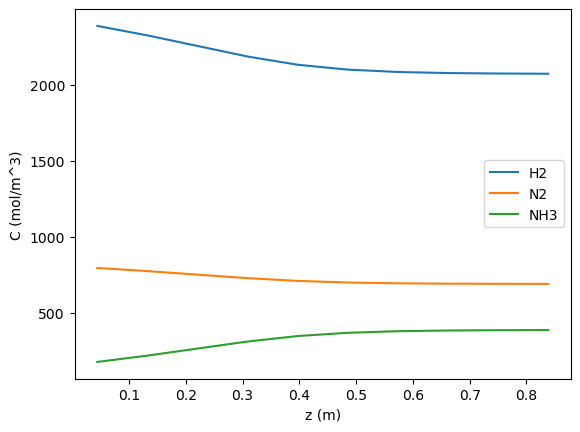

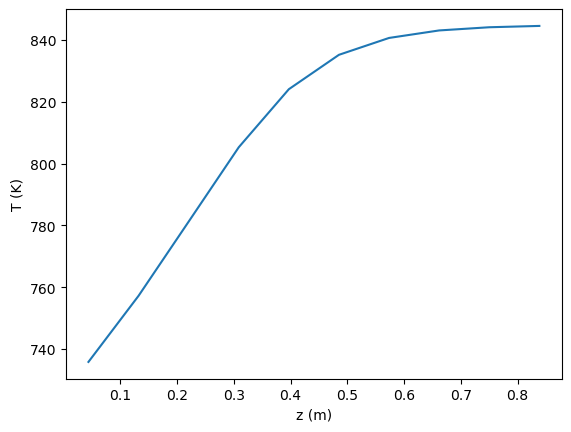

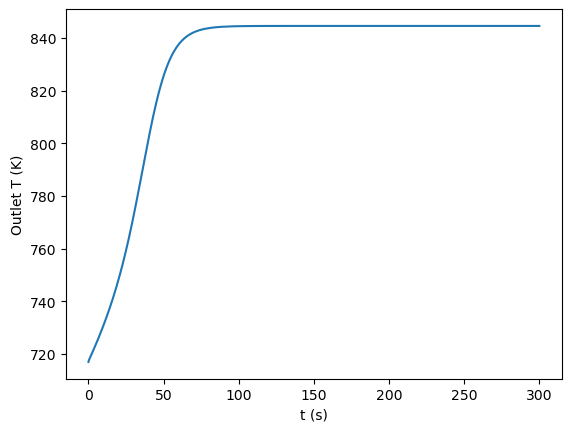

In [148]:
import matplotlib.pyplot as plt

def cell_temperature (i, n):
    C_tot = 0
    for component in y0:
        C_tot = C_tot + C_sol[component][i][n]
    y_i = {}
    for component in y0:
        y_i[component] = C_sol[component][i][n] / C_tot
    T_i = temperature_solver(C_tot, u_sol[i][n], y_i, P0)
    return T_i, C_tot, y_i

z = []
C_end = {}
for component in y0:
    C_end[component] = []
T_end = []
for i in range(N):
    z.append((i + 0.5) * delta_z)
    for component in y0:
        C_end[component].append(C_sol[component][i][-1])
    T_end.append(cell_temperature(i, -1)[0])

for component in y0:
    plt.plot(z, C_end[component], label=component)
plt.xlabel('z (m)')
plt.ylabel('C (mol/m^3)')
plt.legend()
plt.show()

plt.plot(z, T_end)
plt.xlabel('z (m)')
plt.ylabel('T (K)')
plt.show()

T_out_time = []
for n in range(len(sol.t)):
    T_out_time.append(cell_temperature(N-1, n)[0])
plt.plot(sol.t, T_out_time)
plt.xlabel('t (s)')
plt.ylabel('Outlet T (K)')
plt.show()

### Energy balance check

At steady state, the energy flux leaving the bed is equal to the energy flux entering:

$$ \varepsilon_B\,v_{in}\,h_{m,N} = \varepsilon_B\,v_{in}\,h_{m,in} $$

In [149]:
T_N, C_tot_N, y_out = cell_temperature(N-1, -1)
vmix_N, hmix_N, c_pr_N, umix_N, Z_N = properties(T_N, P0, y_out)

Phi_in = eps_B * v_in * h_in #J/(m^2 s)
Phi_out = eps_B * v_in * C_tot_N * hmix_N * vmix_N #J/(m^2 s)

print(f"Outlet temperature: {T_N:.2f} K")
print(f"Outlet NH3 mole fraction: {y_out['NH3']:.4f}")
print(f"Relative enthalpy flux difference: {(Phi_out - Phi_in)/Phi_in:.2e}")
print(f"State C_tot / PR concentration at outlet: {C_tot_N/c_pr_N:.4f}")

Outlet temperature: 844.58 K
Outlet NH3 mole fraction: 0.1231
Relative enthalpy flux difference: -2.38e-04
State C_tot / PR concentration at outlet: 1.0851
